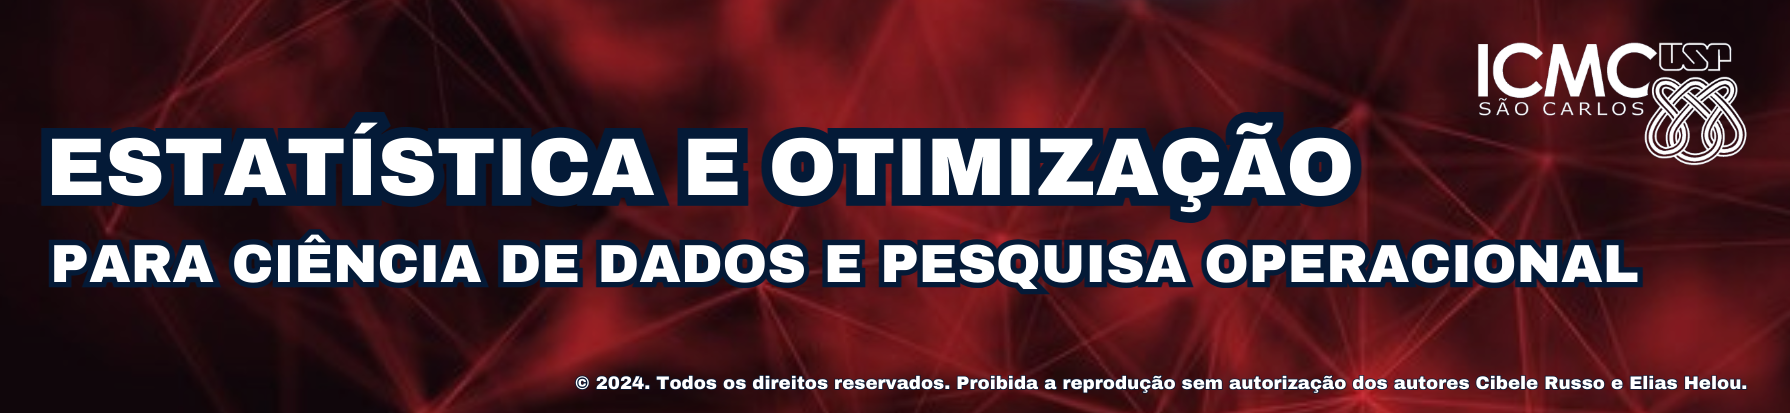

<h1 style = 'text-align: center;'>Resolvendo o Sudoku com MILP</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do vídeo</h2>

1. Sudoku como Viabilidade Binária

    1.1. Regras

    1.2. O Modelo de viabilidade binária

    1.3. Modelando e resolvendo com PuLP

    1.4. Desafios

## 1. Sudoku como Viabilidade Binária

### 1.1. Regras

O Sudoku é um jogo:

- usa um tabuleiro de $L^2 \times L^2$ casas (normalmente $L = 3$)

- o objetivo é preencher cada casa com um e apenas um número inteiro entre $1$ e $L^2$

- algumas casas virão pré-preenchidas (são as dicas)

- o mesmo número não pode aparecer duas vezes:
    - na mesma linha
    - na mesma coluna
    - em um mesmo subquadrado de tamanho $L \times L$ (veja figura)


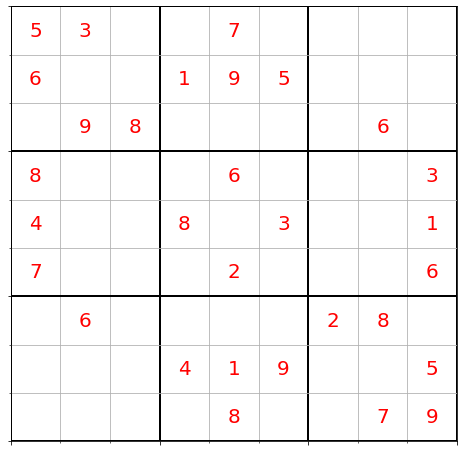

In [1]:
import matplotlib.pyplot as pp
import numpy as np

def display_sudoku( dica, sol = None ):
    
    pp.figure( figsize = ( 8, 8 ) )
    ax = pp.gca()

    L = int( np.round( dica.shape[ 0 ] ** 0.5 ) )

    ax.set_xticks( np.arange( 0, L**2 + 1, 1 ), minor = True )
    ax.set_yticks( np.arange( 0, L**2 + 1, 1 ), minor = True )

    ax.grid( which = 'minor' )

    ax.set_xticks( np.arange( 0, L**2 + 1, L ), [] * L, minor = False )
    ax.set_yticks( np.arange( 0, L**2 + 1, L ), [] * L, minor = False )

    ax.grid( which = 'major', linewidth = 2, color = 'k' )

    for i in range( L ** 2 ):
        for j in range( L ** 2 ):
            if dica[ i, j ] != 0:
                pp.text(
                    j + 0.5, L ** 2 - i - 0.5,
                    str( dica[ i, j ] ),
                    ha = 'center', va = 'center',
                    fontsize = 20, color = 'red'
                    )

    if not ( sol is None ):
        for i in range( L ** 2 ):
            for j in range( L ** 2 ):
                if dica[ i, j ] == 0:
                    pp.text(
                        j + 0.5, L ** 2 - i - 0.5,
                        str( sol[ i, j ] ),
                        ha = 'center', va = 'center',
                        fontsize = 20
                        )

    pp.show()

dica = np.array(
    [
        [5, 3, 0, 0, 7, 0, 0, 0, 0],
        [6, 0, 0, 1, 9, 5, 0, 0, 0],
        [0, 9, 8, 0, 0, 0, 0, 6, 0],
        [8, 0, 0, 0, 6, 0, 0, 0, 3],
        [4, 0, 0, 8, 0, 3, 0, 0, 1],
        [7, 0, 0, 0, 2, 0, 0, 0, 6],
        [0, 6, 0, 0, 0, 0, 2, 8, 0],
        [0, 0, 0, 4, 1, 9, 0, 0, 5],
        [0, 0, 0, 0, 8, 0, 0, 7, 9]
    ]
)

display_sudoku( dica )

### 1.2. O Modelo de Viabilidade Binária

Variáveis de decisão:
$$
 x_{i, j, k} = \begin{cases}
                1 & \text{se o número } k \text{ está na casa }( i, j )\\
                0 & \text{caso contrário}
               \end{cases}
$$

- Observe que são $L^6$ variáveis binárias. Por exemplo, para $L = 3$, temos $729$ variáveis.

- No caso do Sudoku, não temos preferência por uma solução, basta satisfazer as restrições da regra!

- Restrições de somente um número por casa ($L^4$ restrições):
$$
    \sum_{k = 1}^{L^2}x_{i, j, k} = 1\quad ( i, j ) \in \{ 1, 2, \dots, L^2 \}^2
$$

- Restrições de linha ($L^4$ restrições):
$$
    \sum_{j = 1}^{L^2}x_{i, j, k} = 1\quad ( i, k ) \in \{ 1, 2, \dots, L^2 \}^2
$$

- Restrições de coluna ($L^4$ restrições):
$$
    \sum_{i = 1}^{L^2}x_{i, j, k} = 1\quad ( j, k ) \in \{ 1, 2, \dots, L^2 \}^2
$$

- Restrições de sub-quadrados ($L^4$ restrições):
$$
    \sum_{i = 1}^{L}\sum_{j = 1}^{L}x_{( I - 1 )L + i , ( J - 1 )L + j, k} = 1 \quad ( I, J, k ) \in \{ 1, 2, \dots, L \}^2 \times \{ 1, 2, \dots, L^2 \}
$$

- Restrições de dicas (depende do número de casas pré-preenchidas):
$$
    x_{i, j, k} = 1 \quad\text{para toda casa }( i, j )\text{ pré-prenchida com o número }k.
$$


### 1.3. Modelando e resolvendo com PuLP

In [2]:
import pulp
import itertools as it

L = int( np.round( dica.shape[ 0 ] ** 0.5 ) )

# Variáveis:
x = {}
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    x[ i, j, k ] = pulp.LpVariable( name = f'x_({i + 1},{j + 1},{k + 1})', cat = pulp.LpBinary )

# Modelo
p = pulp.LpProblem( 'Sudoku' )

# Apenas um valor em cada quadrado:
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for k in range( L ** 2 ) ) == 1 )

# Restrições de linha:
for i, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for j in range( L ** 2 ) ) == 1 )

# Restrições de coluna:
for j, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for i in range( L ** 2 ) ) == 1 )

# Restrições de sub-quadrados:
for I, J, k in it.product( range( L ), range( L ), range( L ** 2 ) ):
    p += (
        pulp.lpSum( 
            x[ I * L + i, J * L + j, k ] for i, j in it.product( range( L ), repeat = 2 )
            ) == 1
        )

# Restrições de dicas:
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    if dica[ i, j ] != 0:
        p += ( x[ i, j, dica[ i, j ] - 1 ] == 1 )

print( p )

Sudoku:
MINIMIZE
None
SUBJECT TO
_C1: x_(1,1,1) + x_(1,1,2) + x_(1,1,3) + x_(1,1,4) + x_(1,1,5) + x_(1,1,6)
 + x_(1,1,7) + x_(1,1,8) + x_(1,1,9) = 1

_C2: x_(1,2,1) + x_(1,2,2) + x_(1,2,3) + x_(1,2,4) + x_(1,2,5) + x_(1,2,6)
 + x_(1,2,7) + x_(1,2,8) + x_(1,2,9) = 1

_C3: x_(1,3,1) + x_(1,3,2) + x_(1,3,3) + x_(1,3,4) + x_(1,3,5) + x_(1,3,6)
 + x_(1,3,7) + x_(1,3,8) + x_(1,3,9) = 1

_C4: x_(1,4,1) + x_(1,4,2) + x_(1,4,3) + x_(1,4,4) + x_(1,4,5) + x_(1,4,6)
 + x_(1,4,7) + x_(1,4,8) + x_(1,4,9) = 1

_C5: x_(1,5,1) + x_(1,5,2) + x_(1,5,3) + x_(1,5,4) + x_(1,5,5) + x_(1,5,6)
 + x_(1,5,7) + x_(1,5,8) + x_(1,5,9) = 1

_C6: x_(1,6,1) + x_(1,6,2) + x_(1,6,3) + x_(1,6,4) + x_(1,6,5) + x_(1,6,6)
 + x_(1,6,7) + x_(1,6,8) + x_(1,6,9) = 1

_C7: x_(1,7,1) + x_(1,7,2) + x_(1,7,3) + x_(1,7,4) + x_(1,7,5) + x_(1,7,6)
 + x_(1,7,7) + x_(1,7,8) + x_(1,7,9) = 1

_C8: x_(1,8,1) + x_(1,8,2) + x_(1,8,3) + x_(1,8,4) + x_(1,8,5) + x_(1,8,6)
 + x_(1,8,7) + x_(1,8,8) + x_(1,8,9) = 1

_C9: x_(1,9,1) + x_(1,9,2) + x_

In [3]:
p.solve(
    pulp.PULP_CBC_CMD( msg = False )
)

print( pulp.LpStatus[ p.status ] )

Optimal


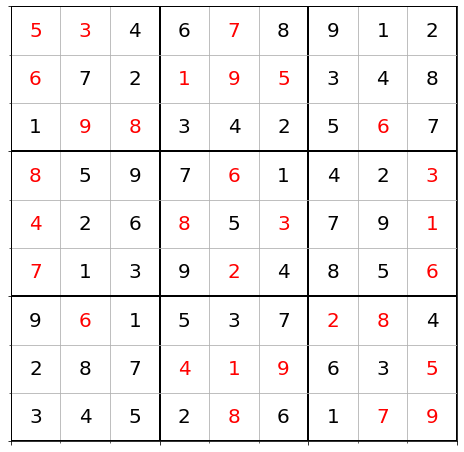

In [4]:
sol = np.empty( ( L ** 2, L ** 2 ), dtype = int )
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    if x[ i, j, k ].value() > 1e-6:
        sol[ i, j ] = k + 1

display_sudoku( dica, sol )

O sudoku é abordado em alguns tutoriais:

<div style="text-align: center;">
    <iframe type="text/html" src="https://coin-or.github.io/pulp/CaseStudies/a_sudoku_problem.html" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>

Outras tentativas:

- <a href="https://pub.towardsai.net/solving-sudoku-with-binary-integer-linear-programming-bilp-b30c194a9266">Usando Excel</a>

- <a href="https://www.mathworks.com/help/optim/ug/sudoku-puzzles-problem-based.html">Usando Matlab</a>

In [5]:
# Problema retirado de https://sudoku-puzzles.net/pt-br/sudoku-16x16-dificil/
dica = np.array(
    [
        [  0,  2,  0,  3,    5,  0,  0,  0,   13,  0,  0,  0,   12,  0,  0, 11 ],
        [  0,  6,  0,  0,    0,  2, 12,  0,    0,  8, 15,  3,    4,  0, 14,  0 ],
        [  0,  0, 12, 14,    0,  4,  8, 11,    0,  0, 16,  0,    0,  0,  0,  0 ],
        [  0,  0,  0, 11,    0,  0,  0,  0,    0,  2,  0, 10,    0,  0,  6, 16 ],

        [  0, 14,  8,  0,    0,  0,  4,  0,   12,  0, 13,  0,    0,  0,  0,  1 ],
        [  0,  0,  5,  0,    3, 15,  0,  0,    9,  0,  0,  1,    6, 14,  0, 12 ],
        [ 15,  0,  0,  0,   12, 11,  6,  1,    0, 14,  0,  0,   10,  0,  0,  0 ],
        [  0,  0,  1,  9,    8,  0,  0,  0,    0,  0,  4,  0,   16, 15, 11,  0 ],

        [  0,  0,  7,  0,    0,  0,  0,  0,    0,  0,  0,  0,    0,  0,  0, 15 ],
        [  2,  0, 11, 13,    6, 14,  0,  0,    3,  0,  7,  0,    0,  0,  5, 10 ],
        [  0,  0,  0,  0,    4,  8,  0,  5,    0,  0,  0,  0,    0,  6, 13,  0 ],
        [  3, 10, 15,  8,    1,  0,  0,  0,    6, 16,  9,  0,    2, 11,  0,  0 ],

        [ 14,  0,  6, 15,    0, 12,  0,  8,    0,  0,  1,  0,    0, 10,  2,  0 ],
        [  0,  0, 16,  0,    0,  1,  0,  0,   15,  0,  0,  0,    0,  0,  0,  0 ],
        [  0,  0,  0,  0,    0,  3, 13, 14,    2,  5,  0,  7,   15,  0,  0,  8 ],
        [ 11,  4,  2,  0,   15,  0, 10,  6,    8, 12,  0, 13,    0,  1,  0,  5 ]
    ]
)

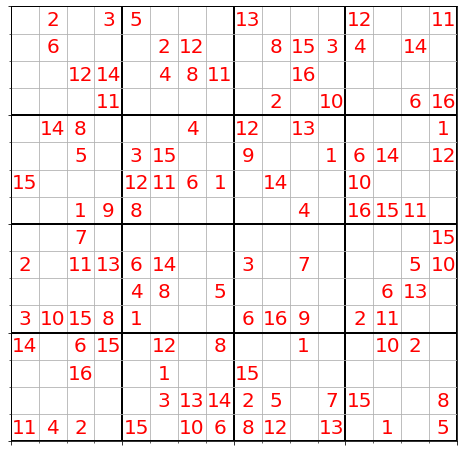

In [6]:
display_sudoku( dica )

Optimal


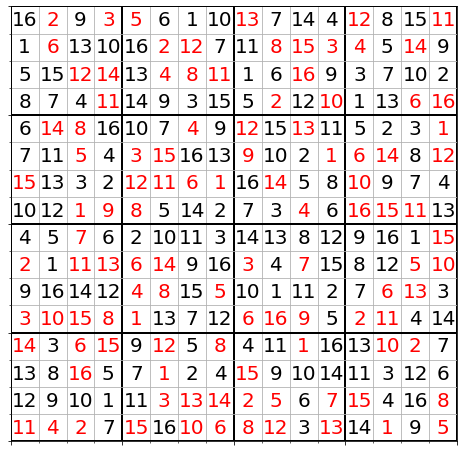

In [7]:
import pulp
import itertools as it

L = int( np.round( dica.shape[ 0 ] ** 0.5 ) )

# Variáveis:
x = {}
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    x[ i, j, k ] = pulp.LpVariable( name = f'x_({i + 1},{j + 1},{k + 1})', cat = pulp.LpBinary )

# Modelo
p = pulp.LpProblem( 'Sudoku' )

# Apenas um valor em cada quadrado:
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for k in range( L ** 2 ) ) == 1 )

# Restrições de linha:
for i, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for j in range( L ** 2 ) ) == 1 )

# Restrições de coluna:
for j, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += ( pulp.lpSum( x[ i, j, k ] for i in range( L ** 2 ) ) == 1 )

# Restrições de sub-quadrados:
for I, J, k in it.product( range( L ), range( L ), range( L ** 2 ) ):
    p += (
        pulp.lpSum( 
            x[ I * L + i, J * L + j, k ] for i, j in it.product( range( L ), repeat = 2 )
            ) == 1
        )

# Restrições de dicas:
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    if dica[ i, j ] != 0:
        p += ( x[ i, j, dica[ i, j ] - 1 ] == 1 )

p.solve(
    pulp.PULP_CBC_CMD( msg = False )
)

print( pulp.LpStatus[ p.status ] )

sol = np.empty( ( L ** 2, L ** 2 ), dtype = int )
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    if x[ i, j, k ].value() > 1e-6:
        sol[ i, j ] = k + 1

display_sudoku( dica, sol )

### 1.4. Desafios

- Procure todas as soluções como no tutorial do PuLP

- Como usar esta formulação para obter problemas de sudoku?

- Implemente para quadrados <a href = 'https://sudoku-puzzles.net/pt-br/sudoku-12x12-dificil/'>heterogêneos</a><br>
  exemplo: $4\times3$ quadrados de $3\times4$ casas, resultando em um problema de $12\times12$ casas

- E quanto ao sudoku 3D?

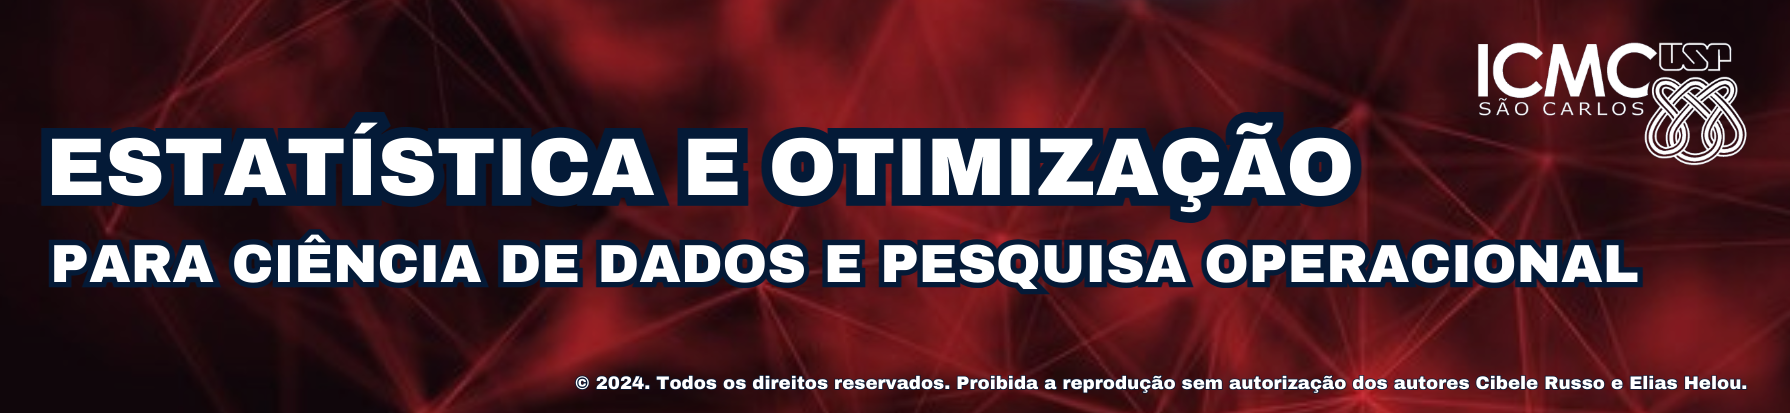

<h1 style = 'text-align: center;'>O Problema do Caixeiro Viajante</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Definição do problema

3. Resolvendo com heurísticas e aproximações

## 1. Definição do Problema

Considere que

- temos $N$ cidades interconectadas

- conhecemos o custo $c_{i, j}$ de viagem entre a cidade $i$ e a cidade $j$

- precisamos visitar todas as cidades uma vez

- precisamos voltar ao ponto inicial

- desejamos minimizar o custo da viagem

Este é o problema do caixeiro viajante (TSP).
<br><br>

O problema do caixeiro viajante

- possui inúmeras aplicações
    - roteamento
        - de veículos de entrega
        - de coleta de lixo
        - ônibus escolares

    - planejamento de CNC
    
    - perfuração de circuitos impressos

    - automatização de armazéns

- pode ser modelado como um problema de otimização em grafos

- é um problema cuja solução exata é muito difícil de obter

- aproximações e heurísticas obtém resultados razoáveis

- serve como base para diversos problemas mais sofisticados


### 1.1. Modelagem em Grafos

Considere um grafo completo não-direcionado (o caso direcionado é semelhante)
$$
    G = ( V, E ).
$$

O problema do caixeiro viajante é equivalente a encontrar um caminho

- que não tenha ciclos disjuntos

- que passe por todos os vértices uma única vez

- que termine onde começou

- cuja soma dos pesos das arestas seja a menor possível

Um caminho cíclico que passa por todos os vértices e que retorna ao ponto inicial é conhecido como circuito hamiltoniano. Ou seja:

> Queremos achar o circuito hamiltoniano de menor custo.


In [ ]:
import networkx as nx
import matplotlib.pyplot as pp
import numpy as np

def gera_grafo( N, p = 1.0, seed = None ):

    if not ( seed is None ):
        np.random.seed( seed )

    G = nx.Graph()
    for i in range( 1, N + 1 ):
        G.add_node( i, pos = tuple( np.random.uniform( size = ( 2, ) ) ) )

    pos = nx.get_node_attributes( G, 'pos' )

    for i in range( 1, N + 1 ):
        for j in range( i + 1, N + 1 ):
            r = np.random.uniform()
            # Conecta vértices com probabilidade igual a p
            if ( i != j ) and ( r <= p ):
                # O peso de cada aresta é a distância euclidiana entre eles
                d = (
                    ( pos[ i ][ 0 ] - pos[ j ][ 0 ] ) ** 2 +
                    ( pos[ i ][ 1 ] - pos[ j ][ 1 ] ) ** 2
                ) ** 0.5
                G.add_edge( i, j, weight = d )

    return G

def plota_grafo( G, edgelist = None, paths = [], source = None, legend = None ):

    pos = nx.get_node_attributes( G, 'pos' )

    pp.figure( figsize = ( 9, 9 ) )

    nx.draw_networkx_nodes( G, pos, node_size = 15 )
    if not ( source is None ):
        pp.scatter( pos[ source ][ 0 ], pos[ source ][ 1 ], s = 30, c = 'r', zorder = 10 )
    nx.draw_networkx_edges( G, pos, edgelist = edgelist, width = 0.2 )

    colors = pp.rcParams[ 'axes.prop_cycle' ].by_key()[ 'color' ]
    lines = []
    for i in range( len( paths ) ):
        p = paths[ i ]
        c = colors[ i + 1 ]
        edgelist = []
        for i, j in zip( p[ : -1 ], p[ 1 : ] ):
            edgelist.append( ( i, j ) )
        lines.append( nx.draw_networkx_edges( G, pos, edgelist = edgelist, width = 3, edge_color = c ) )

    if not ( legend is None ):
        pp.legend( lines[ : len( legend ) ], legend )

    pp.margins( 0.1 )
    pp.axis( 'off' )
    pp.show()

def custo_caminho( G, P ):

    c = 0.0
    for i, j in zip( P[ : -1 ], P[ 1 : ] ):
        c += G.get_edge_data( i, j )[ 'weight' ]
    
    return c


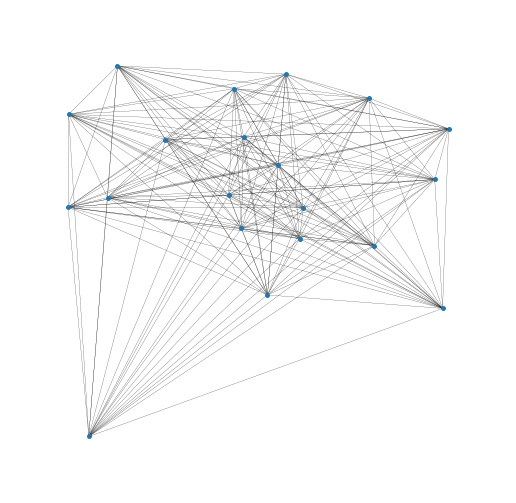

Graph with 20 nodes and 190 edges


In [2]:
N = 20
G = gera_grafo( N, 1.0, 0 )

plota_grafo( G )

print( G )

## 2. Resolvendo com heurísticas e aproximações

### 2.1. Sequencial

Um caminho possível é a sequência $( 1, 2, \dots, N, 1 )$

- é muito rápido
- gera um resultado muito ruim
- útil para inicializar outros métodos

9.072573154507921


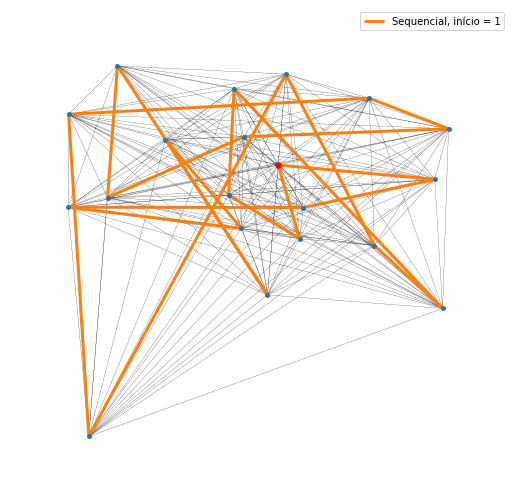

In [3]:
# Sequencial :

P = list( G )
P.append( P[ 0 ] )
print( custo_caminho( G, P ) )
plota_grafo( G, paths = [ P ], source = 1, legend = [ 'Sequencial, início = 1' ] )


<div style="text-align: center;">
    <iframe type="text/html" src="https://networkx.org/documentation/stable/reference/algorithms/approximation.html" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>

In [4]:
import networkx.algorithms.approximation as na

### 2.2. Recozimento Simulado

- rápido
- parte de um ciclo inicial e tenta melhorar
- estocástico (cada execução dá um resultado diferente)
- resultados ruins

6.23851427880907


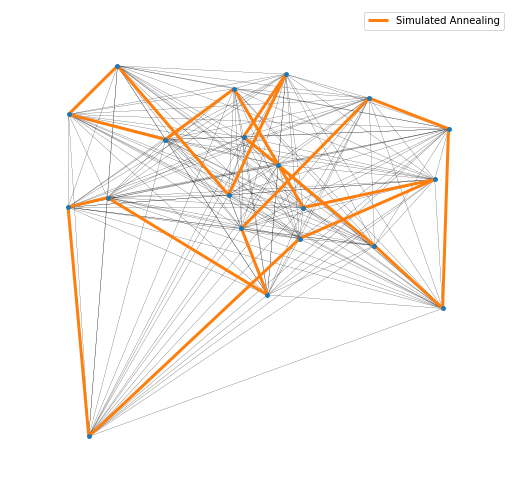

In [5]:
P_sa = na.simulated_annealing_tsp( G, init_cycle = P )
print( custo_caminho( G, P_sa ) )
plota_grafo( G, paths = [ P_sa ], legend = [ 'Simulated Annealing' ] )

### 2.3. Algoritmo Ambicioso

- rápido
- a partir de um ponto, vai para o mais próximo não-visitado
- requer um ponto inicial
- resultados bons


5.3454995624259976


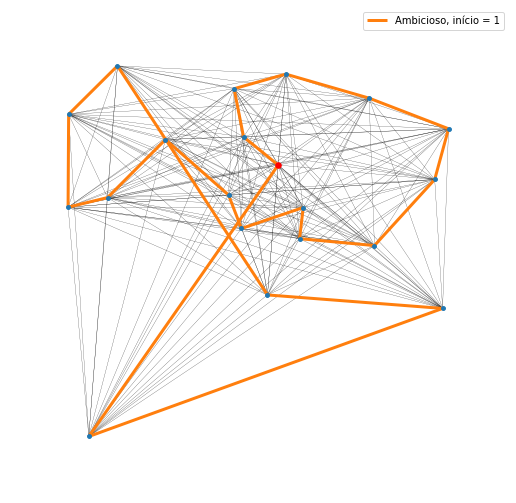

In [6]:
P_g1 = na.greedy_tsp( G, source = 1 )
print( custo_caminho( G, P_g1 ) )
plota_grafo( G, paths = [ P_g1 ], source = 1, legend = [ 'Ambicioso, início = 1' ] )

4.683117005668812


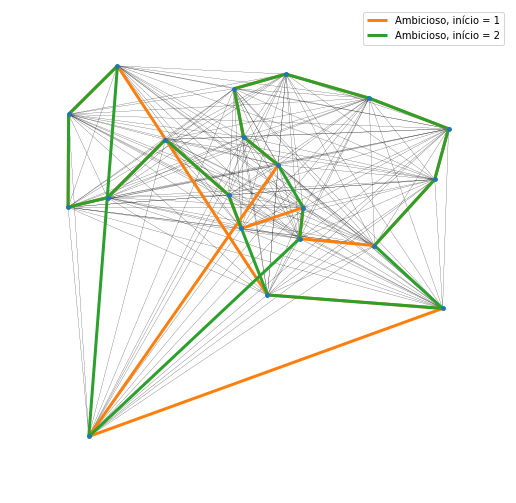

In [7]:
P_g2 = na.greedy_tsp( G, source = 2 )
print( custo_caminho( G, P_g2 ) )
plota_grafo( G, paths = [ P_g1, P_g2 ], legend = [ 'Ambicioso, início = 1', 'Ambicioso, início = 2' ] )

### 2.4. Christofides

- não tão rápido
- resultados muito bons
- garantia de aproximação sob certas condições

<div style="text-align: center;">
    <iframe type="text/html" src="https://pt.wikipedia.org/wiki/Algoritmo_de_Christofides" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px"> 
</div>

4.079723591525398


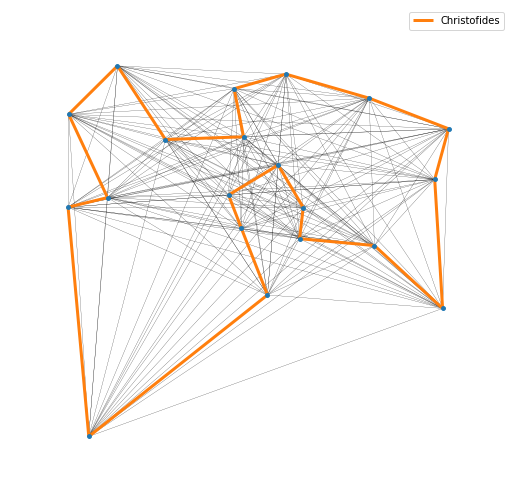

In [8]:
P_c = na.christofides( G )
print( custo_caminho( G, P_c ) )
plota_grafo( G, paths = [ P_c ], legend = [ 'Christofides' ] )

### 2.4. Teste com um Grafo Maior

In [9]:
N = 1000
G = gera_grafo( N, 1.0, 0 )
print( G )

Graph with 1000 nodes and 499500 edges


513.8057357650963


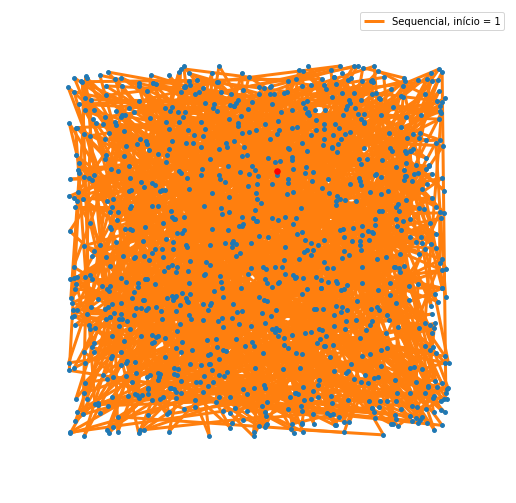

In [10]:
P = list( G )
P.append( P[ 0 ] )
print( custo_caminho( G, P ) )
plota_grafo( G, paths = [ P ], source = 1, legend = [ 'Sequencial, início = 1' ], edgelist = [] )


In [ ]:
P_sa = na.simulated_annealing_tsp( G, init_cycle = P )

513.1964075392616


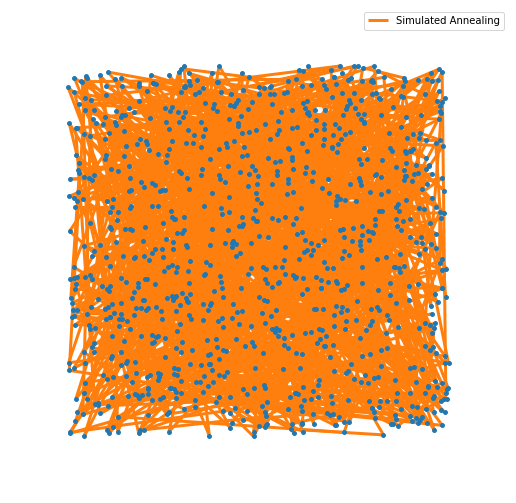

In [12]:
print( custo_caminho( G, P_sa ) )
plota_grafo( G, paths = [ P_sa ], legend = [ 'Simulated Annealing' ], edgelist = [] )

In [13]:
P_g1 = na.greedy_tsp( G, source = 1 )

28.933217878344678


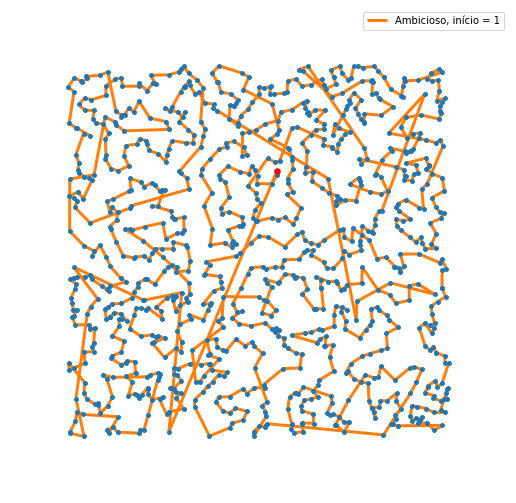

In [14]:
print( custo_caminho( G, P_g1 ) )
plota_grafo( G, paths = [ P_g1 ], source = 1, legend = [ 'Ambicioso, início = 1' ], edgelist = [] )

In [15]:
P_g2 = na.greedy_tsp( G, source = 2 )

28.284504413029353


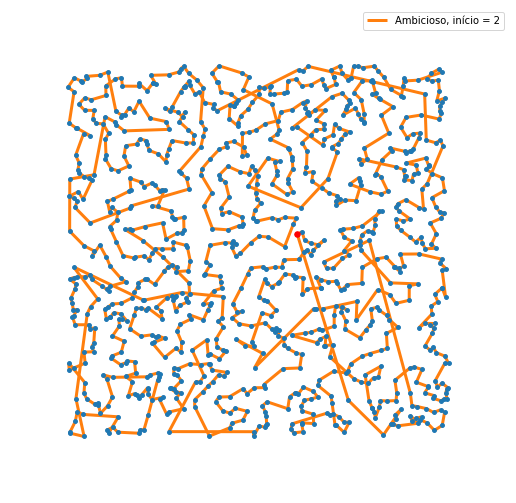

In [16]:
print( custo_caminho( G, P_g2 ) )
plota_grafo( G, paths = [ P_g2 ], source = 2, legend = [ 'Ambicioso, início = 2' ], edgelist = [] )

In [17]:
P_c = na.christofides( G )

26.01598423801953


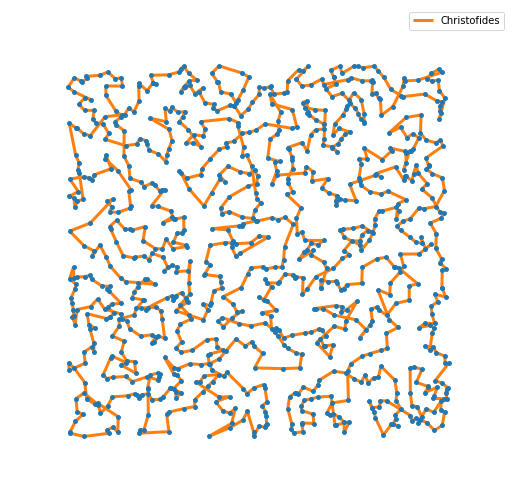

In [18]:
print( custo_caminho( G, P_c ) )
plota_grafo( G, paths = [ P_c ], legend = [ 'Christofides' ], edgelist = [] )

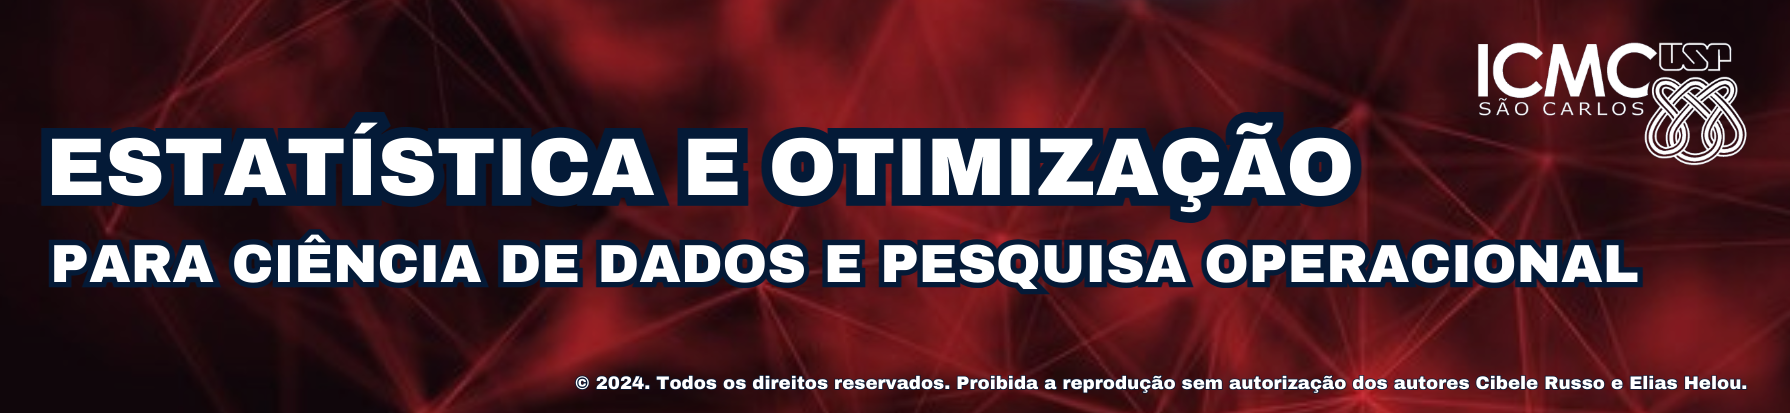

<h1 style = 'text-align: center;'>O Problema do Caixeiro Viajante:<br>Formulação MILP</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Formulação MILP do TSP

3. Resolvendo o modelo

## 1. Formulação MILP do TSP

### 1.1. Modelagem em Grafos

Considere um grafo completo não-direcionado (o caso direcionado é semelhante)
$$
    G = ( V, E ).
$$

O problema do caixeiro viajante é equivalente a encontrar um caminho

- que não tenha ciclos disjuntos

- que passe por todos os vértices uma única vez

- que termine onde começou

- cuja soma dos pesos das arestas seja a menor possível



In [1]:
import networkx as nx
import matplotlib.pyplot as pp
import numpy as np

def gera_grafo( N, p = 1.0, seed = None ):

    if not ( seed is None ):
        np.random.seed( seed )

    G = nx.Graph()
    for i in range( 1, N + 1 ):
        G.add_node( i, pos = tuple( np.random.uniform( size = ( 2, ) ) ) )

    pos = nx.get_node_attributes( G, 'pos' )

    for i in range( 1, N + 1 ):
        for j in range( i + 1, N + 1 ):
            r = np.random.uniform()
            # Conecta vértices com probabilidade igual a p
            if ( i != j ) and ( r <= p ):
                # O peso de cada aresta é a distância euclidiana entre eles
                d = (
                    ( pos[ i ][ 0 ] - pos[ j ][ 0 ] ) ** 2 +
                    ( pos[ i ][ 1 ] - pos[ j ][ 1 ] ) ** 2
                ) ** 0.5
                G.add_edge( i, j, weight = d )

    return G

def plota_grafo( G, edgelist = None, paths = [], source = None, legend = None ):

    pos = nx.get_node_attributes( G, 'pos' )

    pp.figure( figsize = ( 9, 9 ) )

    nx.draw_networkx_nodes( G, pos, node_size = 15 )
    if not ( source is None ):
        pp.scatter( pos[ source ][ 0 ], pos[ source ][ 1 ], s = 30, c = 'r', zorder = 10 )
    nx.draw_networkx_edges( G, pos, edgelist = edgelist, width = 0.2 )

    colors = pp.rcParams[ 'axes.prop_cycle' ].by_key()[ 'color' ]
    lines = []
    for i in range( len( paths ) ):
        p = paths[ i ]
        c = colors[ i + 1 ]
        lines.append( nx.draw_networkx_edges( G, pos, edgelist = p, width = 3, edge_color = c ) )

    if not ( legend is None ):
        pp.legend( lines[ : len( legend ) ], legend )

    pp.margins( 0.1 )
    pp.axis( 'off' )
    pp.show()

def custo_caminho( G, P ):

    c = 0.0
    for e in P:
        c += G.get_edge_data( *e )[ 'weight' ]
    
    return c


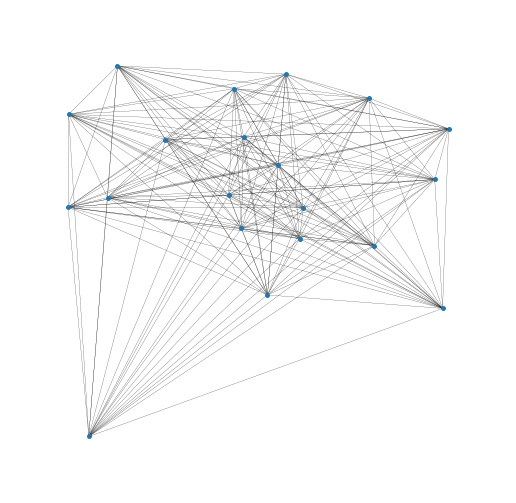

Graph with 20 nodes and 190 edges


In [2]:
N = 20
G = gera_grafo( N, 1.0, 0 )

plota_grafo( G )

print( G )

### 1.1. Modelando

Nossas variáveis de decisão serão
$$
    x_{i, j} = \begin{cases}
                1 & \text{se passamos pela aresta }( i, j )\\
                0 & \text{caso contrário}
               \end{cases}
$$
e denotaremos
$$
    c_{i, j} = \text{custo de ir da cidade }i\text{ para a cidade }j.
$$

<br>

- recordemo-nos que aqui o grafo é não-direcionado

- as variáveis $x_{i, i}$ são eliminadas do problema

- mesmo em grafos não-direcionados, usamos as variáveis $x_{i, j}$ e $x_{j, i}$ para facilitar a modelagem das restrições, como veremos a seguir

#### 1.1.1. Função Objetivo e Direção de Otimização

$$
    \min\quad \sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j}
$$

#### 1.1.2. Restrições

- saímos de cada nó $i$ exatamente uma vez
$$
    \sum_{j \in V \setminus \{i\}}x_{i, j} = 1\quad i \in V
$$

- entramos em cada nó $j$ exatamente uma vez
$$
    \sum_{i \in V \setminus \{j\}}x_{i, j} = 1\quad j \in V
$$

Optimal Solution Found


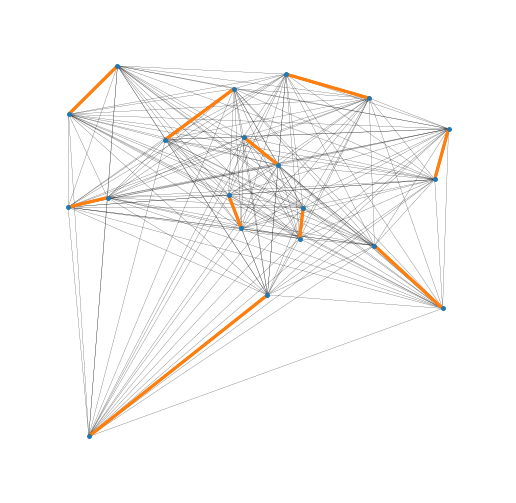

In [3]:
import pulp
import itertools as it

# Conjunto de vértices
V = set( range( 1, N + 1 ) )

# Variáveis:
x = {}
for i, j in it.product( V, V ):
    if i != j:
        x[ i, j ]= pulp.LpVariable(
            name = f'x_({i},{j})', cat = pulp.LpBinary
        )

# Modelo
p = pulp.LpProblem( name = 'Caixeiro_viajante', sense = pulp.LpMinimize )

# Função objetivo
p += pulp.lpSum(
        G.get_edge_data( *ij )[ 'weight' ] * x[ ij ] for ij in x
    )

# Restrições de saída
for i in V:
    p += ( pulp.lpSum( x[ i, j ] for j in V - { i } ) == 1 )

# Restrições de entrada
for j in V:
    p += ( pulp.lpSum( x[ i, j ] for i in V - { j } ) == 1 )

# Resolve o problema
p.solve(
    pulp.PULP_CBC_CMD( msg = False )
)

print( pulp.LpSolution[ p.sol_status ] )

# Arestas do caminho encontrado:
elist = []
for ij in x:
    if x[ ij ].value() > 1e-6:
        elist.append( ij )

plota_grafo( G, paths = [ elist ] )

- nosso modelo está incompleto

- vamos evitar ir e voltar imediatamente:
$$
    x_{i, j} + x_{j, i} \le 1\quad (i, j) \in E
$$

Optimal Solution Found


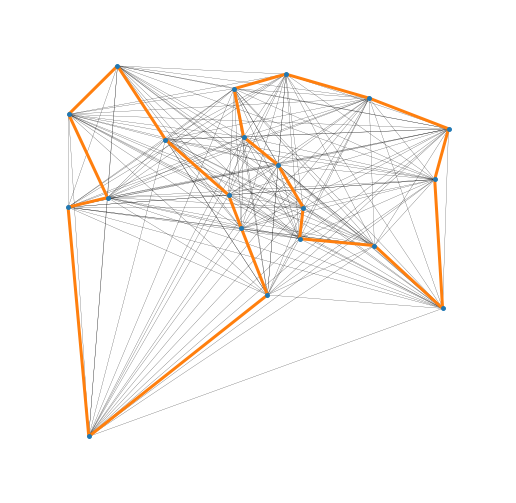

In [4]:
for i in V:
    for j in range( i + 1, N + 1 ):
        p += ( x[ i, j ] + x[ j, i ] <= 1 )

# Resolve o problema
p.solve(
    pulp.PULP_CBC_CMD( msg = False )
)

print( pulp.LpSolution[ p.sol_status ] )

# Arestas do caminho encontrado:
elist = []
for ij in x:
    if x[ ij ].value() > 1e-6:
        elist.append( ij )

plota_grafo( G, paths = [ elist ] )    

#### 1.4. Eliminando Ciclos

Para eliminar subciclos há algumas opções

- incluir restrições para proibir todos os ciclos com menos de $N$ arestas

- incluir restrições para proibir os subciclos relevantes:

    1. resolver o problema

    2. verificar se há subciclos

    3. se houver, incluir restrição para evitá-los e voltar para o passo 1
    

- forçar que exista um ciclo com $N$ arestas


A terceira opção pode ser realizada de forma interessante:

- criamos variáveis $y_1, y_2, \dots, y_N$

- obrigamos que se $x_{i, j} = 1$, então $y_j \ge y_i + 1$

- a princípio, isto impede qualquer ciclo

- então excluímos um nó destas restrições

- isto obriga que todos ciclos contenham aquele nó

- para exigir que se $x_{i, j} = 1$, então $y_j \ge y_i + 1$, fazemos
$$
    y_j \ge y_i + 1x_{i, j}
$$

- entretanto, se $x_{i, j} = 0$ e $x_{j, i} = 0$, isto resultaria em $y_j = y_i$

- fazemos, então, para $K \ge N$,
$$
    y_j \ge y_i + 1x_{i, j} - K( 1 - x_{i, j} ) \quad i \in V \setminus \{ 1 \},\ j \in V \setminus \{ 1, i \}
$$


### 1.5. O Modelo Completo

Nosso modelo completo é o seguinte
$$
    \begin{array}{rrcrl}
        \min & \displaystyle\sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j}\\[1.5em]
        \text{s.a:} & \displaystyle\sum_{j \in V \setminus \{i\}}x_{i, j} &=& 1&\quad i \in V\\[1.5em]
                    & \displaystyle\sum_{i \in V \setminus \{j\}}x_{i, j} &=& 1&\quad j \in V\\[1.5em]
                    & y_i + 1x_{i, j} - K( 1 - x_{i, j} ) & \le& y_j&  \quad i \in V \setminus \{ 1 \},\ j \in V \setminus \{ 1, i \}
    \end{array}
$$

## 2. Resolvendo o Modelo

Agora que temos o modelo completo em mãos, podemos resolvê-lo.

In [5]:
import pulp

def tsp( G, solver = pulp.PULP_CBC_CMD( msg = False ) ):

    # Conjunto de vértices
    V = set( G.nodes )

    # Variáveis:
    x = {}
    for i, j in G.edges:
        if i != j:
            x[ i, j ]= pulp.LpVariable(
                name = f'x_({i},{j})', cat = pulp.LpBinary
            )
            x[ j, i ]= pulp.LpVariable(
                name = f'x_({j},{i})', cat = pulp.LpBinary
            )

    # Modelo
    p = pulp.LpProblem( name = 'Caixeiro_viajante', sense = pulp.LpMinimize )

    # Função objetivo
    p += pulp.lpSum(
            G.get_edge_data( *ij )[ 'weight' ] * x[ ij ] for ij in x
        )

    # Restrições de saída
    for i in V:
        p += ( pulp.lpSum( x[ i, j ] for j in V - { i } ) == 1 )

    # Restrições de entrada
    for j in V:
        p += ( pulp.lpSum( x[ i, j ] for i in V - { j } ) == 1 )

    # Restrições de ciclo
    i_out = list( G.nodes )[ -1 ]
    y = {}
    for i in V - { i_out }:
        y[ i ] = pulp.LpVariable( name = f'y({i})', cat = pulp.LpContinuous )

    for i, j in x:
        if ( i != i_out ) and ( j != i_out ):
            p += ( y[ i ] >= y[ j ] + x[ i, j ] - len( V ) * ( 1 - x[ i, j ] ) )

    # Resolve o problema
    p.solve(
        solver
    )

    print( 'Solution status: ' + pulp.LpSolution[ p.sol_status ] )
    print( 'Solver status  : ' + pulp.LpStatus[ p.status ] )

    elist = []
    for ij in x:
        if x[ ij ].value() > 1e-6:
            elist.append( ij )

    print( 'Custo          :', custo_caminho( G, elist ) )

    return elist

Solution status: Optimal Solution Found
Solver status  : Optimal
Custo          : 4.079723591525397


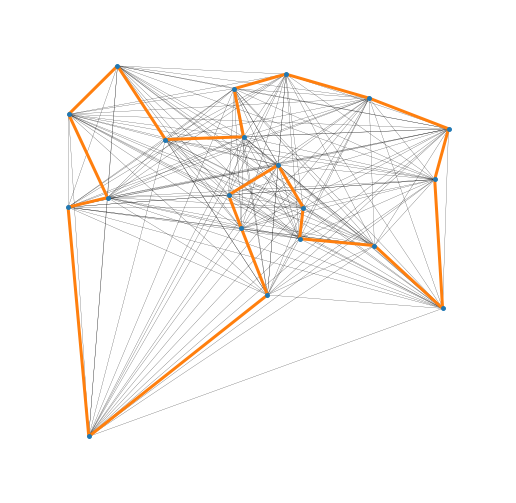

In [6]:
elist = tsp( G )
plota_grafo( G, paths = [ elist ] )

Atenção

- para ter o solver `GUROBI` disponível, precisamos instalar o pacote `gurobipy`

- para ter o solver `COIN_CMD` disponível, o pacote COIN-OR deve estar apropriadamente configurado no seu sistema

- solvers terminados em `_CMD` são executáveis

- solvers terminados em `_DLL` são bibliotecas compartilhadas

- os outros são de módulos do Python

In [18]:
print( pulp.listSolvers( onlyAvailable=True ) )

['CyLP', 'GUROBI', 'PULP_CBC_CMD', 'COIN_CMD', 'COINMP_DLL', 'SCIP_PY']


Restricted license - for non-production use only - expires 2026-11-23
Solution status: Optimal Solution Found
Solver status  : Optimal
Custo          : 4.079723591525397


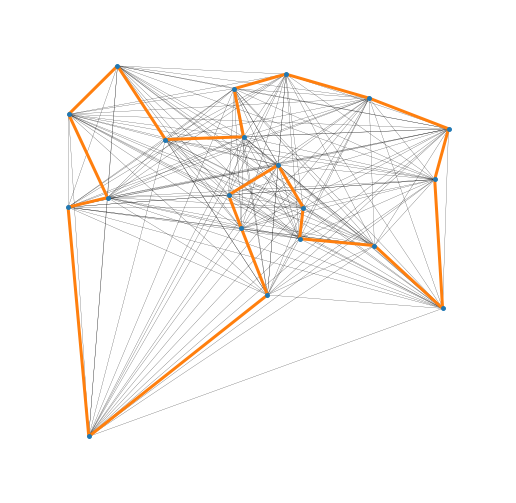

In [8]:
elist = tsp( G, pulp.GUROBI( msg = False ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Optimal Solution Found
Solver status  : Optimal
Custo          : 4.079723591525397


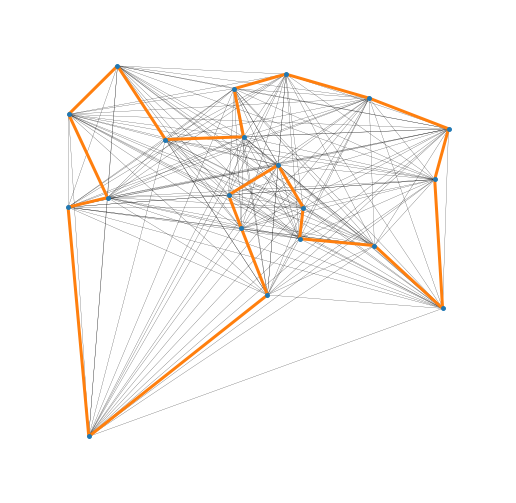

In [9]:
elist = tsp( G, pulp.COIN_CMD( msg = False ) )
plota_grafo( G, paths = [ elist ] )

O gurobi livre permite até $2000$ variáveis, nosso modelo possui, para um grafo de tamanho $N$,

- $N( N - 1 )$ variáveis binárias

- $N - 1$ variáveis contínuas,

- ou seja $N^2 - 1$ variáveis no total

- portanto, $N^2 - 1 \le 2000$, i.e., $N \le \sqrt{2001} \approx 44.7$

In [10]:
G = gera_grafo( 44, seed = 0 )

Solution status: Optimal Solution Found
Solver status  : Optimal
Custo          : 5.578146160261417


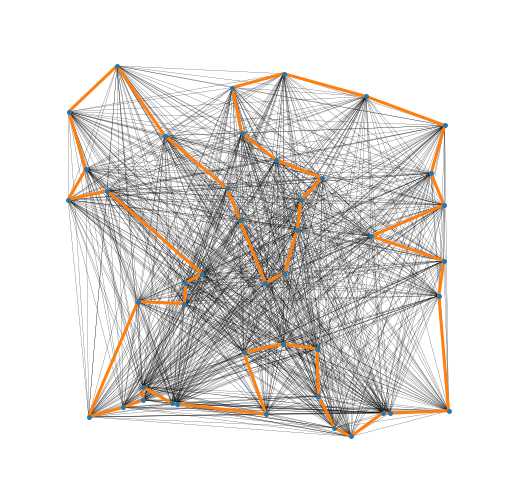

In [11]:
elist = tsp( G, pulp.GUROBI( msg = False, timeLimit = 60 ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Solution Found
Solver status  : Optimal
Custo          : 6.146960533759611


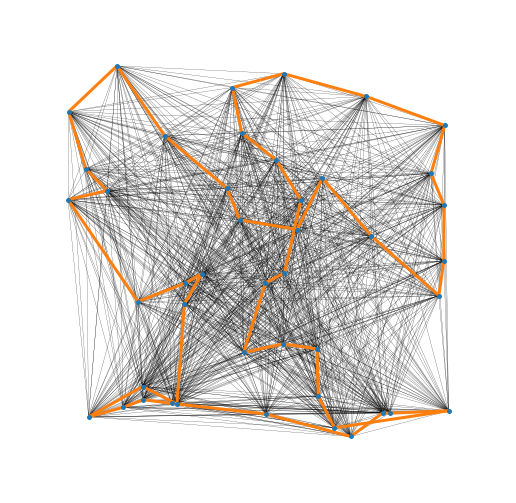

In [12]:
elist = tsp( G, solver = pulp.PULP_CBC_CMD( msg = False, timeLimit = 60 ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Solution Found
Solver status  : Optimal
Custo          : 6.146960533759611


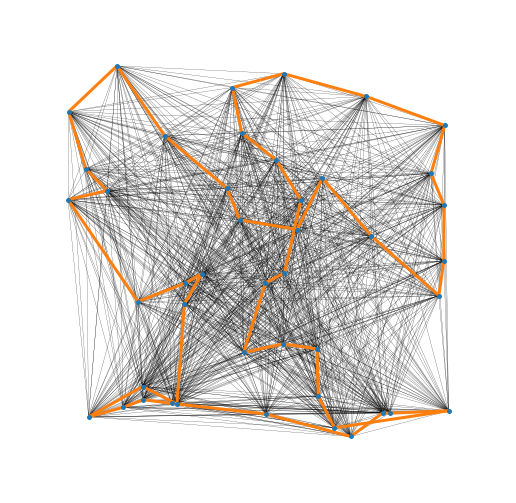

In [13]:
elist = tsp( G, solver = pulp.PULP_CBC_CMD( msg = False, timeLimit = 120 ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Solution Found
Solver status  : Optimal
Custo          : 6.420514434198776


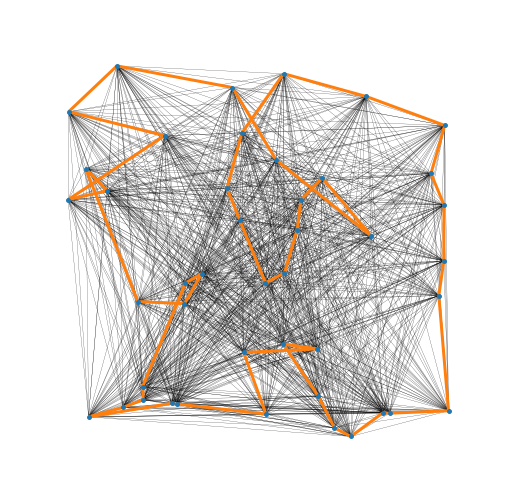

In [14]:
elist = tsp( G, solver = pulp.COIN_CMD( msg = False, timeLimit = 60 ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Solution Found
Solver status  : Optimal
Custo          : 6.510575962080697


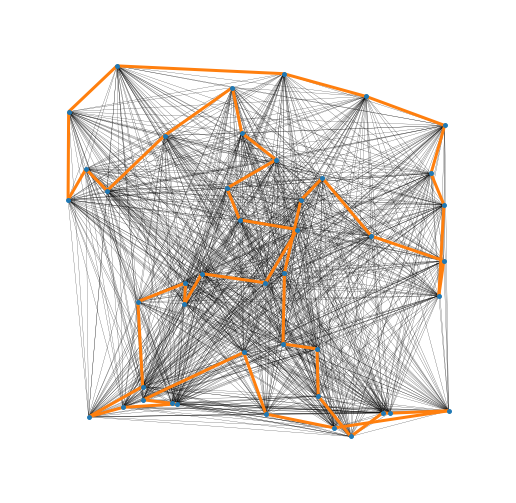

In [15]:
elist = tsp( G, solver = pulp.PULP_CBC_CMD( msg = False, timeLimit = 10 ) )
plota_grafo( G, paths = [ elist ] )

Solution status: Solution Found
Solver status  : Optimal
Custo          : 8.341615191146246


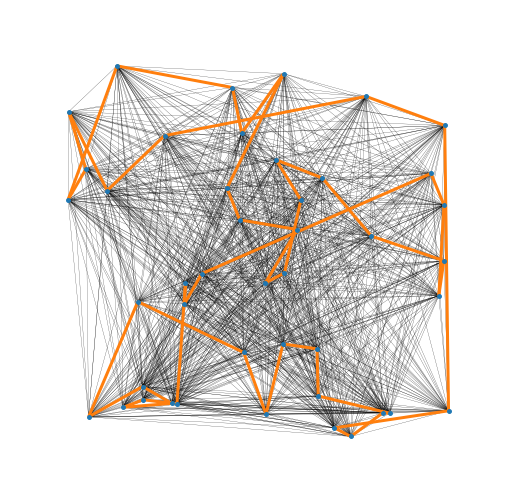

In [16]:
elist = tsp( G, solver = pulp.PULP_CBC_CMD( msg = False, timeLimit = 5 ) )
plota_grafo( G, paths = [ elist ] )

- interfaces genéricas facilitam testes com diversos solvers

- no PuLP, o status do solver pode confundir o usuário

- se você tem um solver para usar em todos os casos, tente usar a interface nativa dele

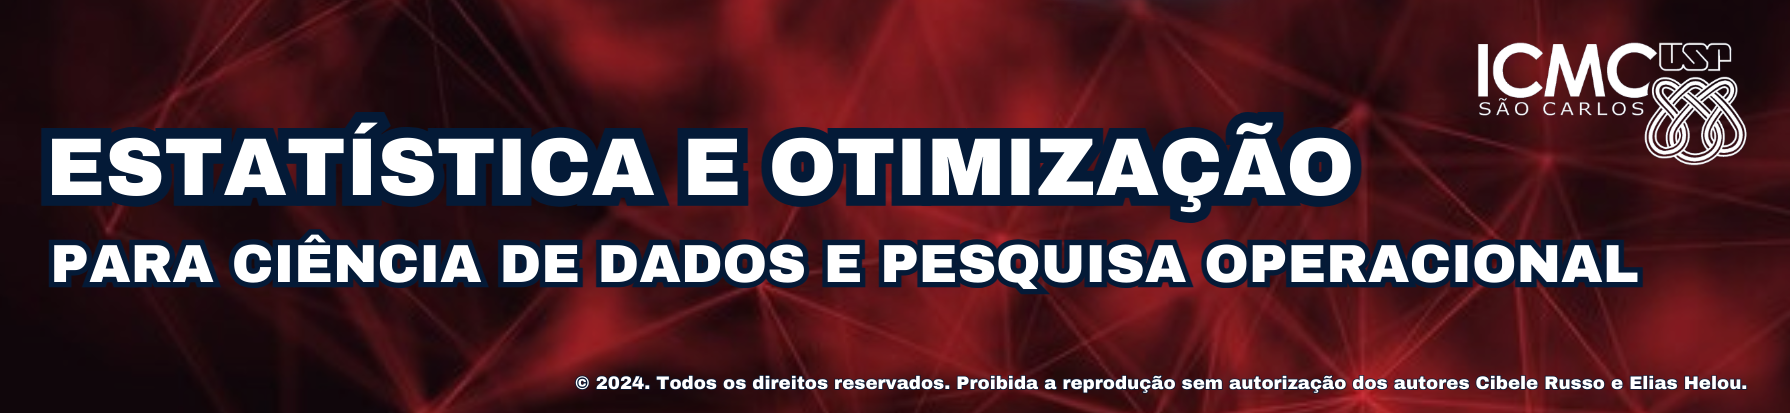

<h1 style = 'text-align: center;'>Documentação como Recurso<br> de Aprendizado</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Seleção de fontes

2. Resolvendo o _vehicle routing problem_

## 1. Seleção de Fontes

- uma grande parte do trabalho do praticante de otimização é atualizar-se

- o profissional bem sucedido sabe escolher suas fontes

### 1.1. Critérios

Não devemos nos debruçar à primeira fonte encontrada

Alguns critérios a considerar quando decidir por fontes na web
- reputação e precisão

- clareza

- profundidade

### 1.2. Objetivos

É necessário definir o objeto desejado nas fontes

Por exemplo, para treinar a modelagem e solução de MILPs, desejamos

1. obter problemas para modelar

2. obter dados para estes modelos

3. reproducibilidade e confirmação de resultados

4. um recurso em caso de dificuldade

5. evitar fontes excessivamente dependentes do produto

### 1.3. Exemplos

Alguns exemplos de fontes

- https://www.mosek.com/

- https://www.cvxpy.org/index.html

- https://www.gurobi.com/

- https://www.ibm.com/br-pt/products/ilog-cplex-optimization-studio

- https://developers.google.com/optimization


## 2. Resolvendo o _Vehicle Routing Problem_

Resolveremos o exemplo de roteamento dado em

https://developers.google.com/optimization/routing/vrp


### 2.1. Problema

- temos um conjunto $K$ de veículos para entregas

- temos um grafo onde um vértice é o depósito

- todos os demais vértices são destinos

- o objetivo é minimizar a maior distância percorrida por um veículo

### 2.2. Modelo

- as variáveis de decisão serão:
$$
    x_{i, j, k} = \begin{cases}
                    1 & \text{se o veículo }k\text{ passa pela aresta }( i, j )\\
                    0 & \text{caso contrário}
                  \end{cases}
$$

- denotaremos
$$
    c_{i, j} = \text{custo de ir do vértice }i\text{ para o vértice }j.
$$

- uma forma de minimizar o máximo é a seguinte
$$
    \begin{array}{rlcrr}
        \min & v\\
        \text{s.a:} & \displaystyle\sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j, k} &\le& v& \quad k \in K
    \end{array}
$$

- todo carro sai e chega no depósito
$$
    \begin{array}{rlcrr}
        \min & v\\
        \text{s.a:} & \displaystyle\sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j, k} &\le& v& k \in K\\[1.5em]
                    & \displaystyle \sum_{j \in V \setminus \{ 1 \}}x_{1, j, k} &=& 1& \quad k \in K\\[1.5em]
                    & \displaystyle \sum_{i \in V \setminus \{ 1 \}}x_{i, 1, k} &=& 1& \quad k \in K
    \end{array}
$$

- adicionando restrições de TSP para os demais nós, teremos<br> (com $M \ge N$, o número de vértices)
$$
    \begin{array}{rlcrl}
        \min & v\\
        \text{s.a:} & \displaystyle\sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j, k} &\le& v& \quad k \in K\\[1.5em]
                    & \displaystyle \sum_{j \in V \setminus \{ 1 \}}x_{1, j, k} &=& 1& \quad k \in K\\[1.5em]
                    & \displaystyle \sum_{i \in V \setminus \{ 1 \}}x_{i, 1, k} &=& 1& \quad k \in K\\[1.5em]
                    & \displaystyle\sum_{k \in K}\sum_{j \in V \setminus \{i\}}x_{i, j, k} &=& 1&\quad i \in V \setminus \{ 1 \}\\[1.5em]
                    & \displaystyle\sum_{k \in K}\sum_{i \in V \setminus \{j\}}x_{i, j, k} &=& 1&\quad j \in V \setminus \{ 1 \}\\[1.5em]
        & y_{i, k} + 1x_{i, j, k} - M( 1 - x_{i, j, k} ) & \le& y_{j, k}&  \quad i \in V \setminus \{ 1 \},\ j \in V \setminus \{ 1, i \}, k \in K
    \end{array}
$$


- o carro que entra em um nó tem que ser o mesmo que sai
$$
    \begin{array}{rlcrl}
        \min & v\\
        \text{s.a:} & \displaystyle\sum_{i \in V}\sum_{j \in V \setminus \{i\}}c_{i, j}x_{i, j, k} &\le& v& \quad k \in K\\[1.5em]
                    & \displaystyle \sum_{j \in V \setminus \{ 1 \}}x_{1, j, k} &=& 1& \quad k \in K\\[1.5em]
                    & \displaystyle \sum_{i \in V \setminus \{ 1 \}}x_{i, 1, k} &=& 1& \quad k \in K\\[1.5em]
                    & \displaystyle\sum_{k \in K}\sum_{j \in V \setminus \{i\}}x_{i, j, k} &=& 1&\quad i \in V \setminus \{ 1 \}\\[1.5em]
                    & \displaystyle\sum_{k \in K}\sum_{i \in V \setminus \{j\}}x_{i, j, k} &=& 1&\quad j \in V \setminus \{ 1 \}\\[1.5em]
                    & \displaystyle\sum_{i \in V \setminus \{j\}}x_{i, j, k} - \sum_{i \in V \setminus \{j\}}x_{j, i, k} &=& 0&\quad j, k \in V \times K\\[1.5em]
        & y_{i, k} + 1x_{i, j, k} - M( 1 - x_{i, j, k} ) & \le& y_{j, k}&  \quad i \in V \setminus \{ 1 \},\ j \in V \setminus \{ 1, i \}, k \in K
    \end{array}
$$


In [1]:
# Matriz de distâncias conforme
# https://developers.google.com/optimization/routing/vrp

c = [
      [0, 548, 776, 696, 582, 274, 502, 194, 308, 194, 536, 502, 388, 354, 468, 776, 662],
      [548, 0, 684, 308, 194, 502, 730, 354, 696, 742, 1084, 594, 480, 674, 1016, 868, 1210],
      [776, 684, 0, 992, 878, 502, 274, 810, 468, 742, 400, 1278, 1164, 1130, 788, 1552, 754],
      [696, 308, 992, 0, 114, 650, 878, 502, 844, 890, 1232, 514, 628, 822, 1164, 560, 1358],
      [582, 194, 878, 114, 0, 536, 764, 388, 730, 776, 1118, 400, 514, 708, 1050, 674, 1244],
      [274, 502, 502, 650, 536, 0, 228, 308, 194, 240, 582, 776, 662, 628, 514, 1050, 708],
      [502, 730, 274, 878, 764, 228, 0, 536, 194, 468, 354, 1004, 890, 856, 514, 1278, 480],
      [194, 354, 810, 502, 388, 308, 536, 0, 342, 388, 730, 468, 354, 320, 662, 742, 856],
      [308, 696, 468, 844, 730, 194, 194, 342, 0, 274, 388, 810, 696, 662, 320, 1084, 514],
      [194, 742, 742, 890, 776, 240, 468, 388, 274, 0, 342, 536, 422, 388, 274, 810, 468],
      [536, 1084, 400, 1232, 1118, 582, 354, 730, 388, 342, 0, 878, 764, 730, 388, 1152, 354],
      [502, 594, 1278, 514, 400, 776, 1004, 468, 810, 536, 878, 0, 114, 308, 650, 274, 844],
      [388, 480, 1164, 628, 514, 662, 890, 354, 696, 422, 764, 114, 0, 194, 536, 388, 730],
      [354, 674, 1130, 822, 708, 628, 856, 320, 662, 388, 730, 308, 194, 0, 342, 422, 536],
      [468, 1016, 788, 1164, 1050, 514, 514, 662, 320, 274, 388, 650, 536, 342, 0, 764, 194],
      [776, 868, 1552, 560, 674, 1050, 1278, 742, 1084, 810, 1152, 274, 388, 422, 764, 0, 798],
      [662, 1210, 754, 1358, 1244, 708, 480, 856, 514, 468, 354, 844, 730, 536, 194, 798, 0],
]

In [11]:
import pulp
import itertools as it

N = len( c )
M = 4

# Conjunto de vértices
V = set( range( N ) )
K = set( range( M ) )

# Depósito
v_dep = 5

# Variáveis:
x = {}
for i, j, k in it.product( V, V, K ):
    if i != j:
        x[ i, j, k ]= pulp.LpVariable(
            name = f'x_({i},{j},{k})', cat = pulp.LpBinary
        )
y = {}
for i, k in it.product( V - { v_dep }, K ):
    y[ i, k ]= pulp.LpVariable( name = f'y_({i},{k})', cat = pulp.LpContinuous )

# Modelo
p = pulp.LpProblem( name = 'VRP', sense = pulp.LpMinimize )

# Função objetivo
v = pulp.LpVariable( name = 'v', cat = pulp.LpContinuous )
p += v
for k in K:
    p += (
        pulp.lpSum(
            c[ i ][ j ] * x[ i, j, k ] for i, j in it.product( V, V ) if i != j
        ) <= v
    )

# Todo carro sai do depósito
for k in K:
    p += (
        pulp.lpSum( x[ v_dep, j, k ] for j in V - { v_dep } ) == 1
    )
# Todo carro chega no depósito
for k in K:
    p += (
        pulp.lpSum( x[ i, v_dep, k ] for i in V - { v_dep } ) == 1
    )
# Restrições de saída
for i in V - { v_dep }:
    p += (
        pulp.lpSum(
            x[ i, j, k ] for j, k in it.product( V - { i }, K )
        ) == 1
    )
# Restrições de entrada
for j in V - { v_dep }:
    p += (
        pulp.lpSum(
            x[ i, j, k ] for i, k in it.product( V - { j }, K )
        ) == 1
    )
# Continuidade do caminho:
for i, k in it.product( V, K ):
    p += (
        pulp.lpSum(
            x[ i, j, k ] for j in V - { i }
        ) == \
        pulp.lpSum(
            x[ j, i, k ] for j in V - { i }
        )
    )
# Prevenção de ciclo:
for i, j, k in x:
    if ( i != v_dep ) and ( j != v_dep ):
        p += ( y[ i, k ] >= y[ j, k ] + x[ i, j, k ] - len( V ) * ( 1 - x[ i, j, k ] ) )

# p.solve(
#     pulp.PULP_CBC_CMD( msg = False )
# )
p.solve(
    pulp.GUROBI( msg = False, timeLimit = 20 )
)


0

In [12]:
print( pulp.LpSolution[ p.sol_status ] )
print( pulp.LpStatus[ p.status ] )
print( p.objective.value() )

No Solution Exists
Not Solved
2100.0


In [13]:
import plotly.graph_objects as go

# Locais conforme
# https://developers.google.com/optimization/routing/vrp

locs = [
    ( 456, -320 ), 
    ( 228, -0   ),   
    ( 912, -0   ),   
    ( 0  , -80  ),    
    ( 114, -80  ),  
    ( 570, -160 ), 
    ( 798, -160 ), 
    ( 342, -240 ), 
    ( 684, -240 ), 
    ( 570, -400 ), 
    ( 912, -400 ), 
    ( 114, -480 ), 
    ( 228, -480 ), 
    ( 342, -560 ), 
    ( 684, -560 ), 
    ( 0  , -640 ),   
    ( 798, -640 )
]

X = list( { l[ 0 ] for l in locs } )
Y = list( { l[ 1 ] for l in locs } )

w_ruas = 10

x_ruas = []
y_ruas = []
for y_r in Y:
    x_ruas += [ min( X ), max( X ), None ]
    y_ruas += [ y_r, y_r, None ]
h_ruas = go.Scatter(
    mode = 'lines',
    x = x_ruas,
    y = y_ruas,
    line = { 'width': w_ruas, 'color': 'rgba( 0, 0, 255, 0.1 )' },
    hoverinfo = 'none',
    hovertemplate = None
)
h_cs = go.Scatter(
    mode = 'lines',
    x = x_ruas,
    y = y_ruas,
    line = { 'width': 1, 'color': 'white', 'dash': 'dash' },
    hoverinfo = 'none',
    hovertemplate = None
)
x_ruas = []
y_ruas = []
for x_r in X:
    x_ruas += [ x_r, x_r, None ]
    y_ruas += [ min( Y ), max( Y ), None ]
v_ruas = go.Scatter(
    mode = 'lines',
    x = x_ruas,
    y = y_ruas,
    line = { 'width': w_ruas, 'color': 'rgba( 0, 0, 255, 0.1 )' },
    hoverinfo = 'none',
    hovertemplate = None
)
v_cs = go.Scatter(
    mode = 'lines',
    x = x_ruas,
    y = y_ruas,
    line = { 'width': 1, 'color': 'white', 'dash': 'dash' },
    hoverinfo = 'none',
    hovertemplate = None
)

x_esqs = []
y_esqs = []
for x_e, y_e in it.product( X, Y ):
    x_esqs.append( x_e )
    y_esqs.append( y_e )

v_esqs = go.Scatter(
    x = x_esqs,
    y = y_esqs,
    mode = 'markers',
    marker = { 'size': w_ruas + 2, 'color': 'white' },
    hoverinfo = 'none',
    hovertemplate = None
)

v_verts = go.Scatter(
    x = [ l[ 0 ] for l in locs ],
    y = [ l[ 1 ] for l in locs ],
    mode = 'markers+text',
    marker = {
        'size': w_ruas + 10,
        'line': { 'color': 'black', 'width': 2 },
        'color': [ 'white' if i != v_dep else 'gray' for i in V ]
    },
    hoverinfo = 'none',
    hovertemplate = None
)
v_verts.text = [ i for i, l in enumerate( locs ) ]


In [14]:
paths = []

for k in K:
    curr_x = []
    curr_y = []
    for i, j in it.product( V, V ):
        if i != j:
            if x[ i, j, k ].value() > 1e-6:
                x_init, y_init = locs[ i ]
                x_end, y_end = locs[ j ]

                del_x = w_ruas / 3 if y_init < y_end else -w_ruas / 3
                curr_x += [ locs[ i ][ 0 ] + del_x ] * 2 + [ None ]
                curr_y += [ y_init, y_end ] + [ None ]

                del_y = w_ruas / 3 if x_init > x_end else -w_ruas / 3
                curr_y += [ locs[ j ][ 1 ] + del_y ] * 2 + [ None ]
                curr_x += [ x_init, x_end ] + [ None ]
                                               
    paths.append(
        go.Scatter(
            mode = 'lines',
            x = curr_x,
            y = curr_y,
            line = { 'width': 2 },
            opacity = 0.75
        )
    )

# Altere os índices lista 'path' para ver
# apenas o caminho de interesse
fig = go.Figure(
    data = paths[ 0 : 4 ] + [ h_ruas, h_cs, v_ruas,v_cs, v_esqs, v_verts ],
    layout = {
        'xaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( min( X ) - 5, max( X ) + 5 )
            ),
        'yaxis'        : dict(
            showgrid = False,
            zeroline = False,
            showticklabels = False,
            range = ( min( Y ) - 20, max( Y ) + 20 ),
            scaleanchor = 'x',
            scaleratio = 1.0
            ),
        'showlegend': False,
        'margin': dict( b = w_ruas, l = w_ruas, r = w_ruas, t = w_ruas ),
        'plot_bgcolor': 'white'
        }
)

fig.show()


In [15]:
for k in K:
    val = 0.0
    for i, j in it.product( V, V ):
        if i != j:
            val += c[ i ][ j ] * x[ i, j, k ].value()
    print( k, val )

0 1964.0
1 2100.0
2 1484.0
3 1460.0
